# 3. How DeepEval works

Everything in DeepEval follows one pattern:

> **test case** → **metric** → **result** (score, threshold, pass or fail, reason)

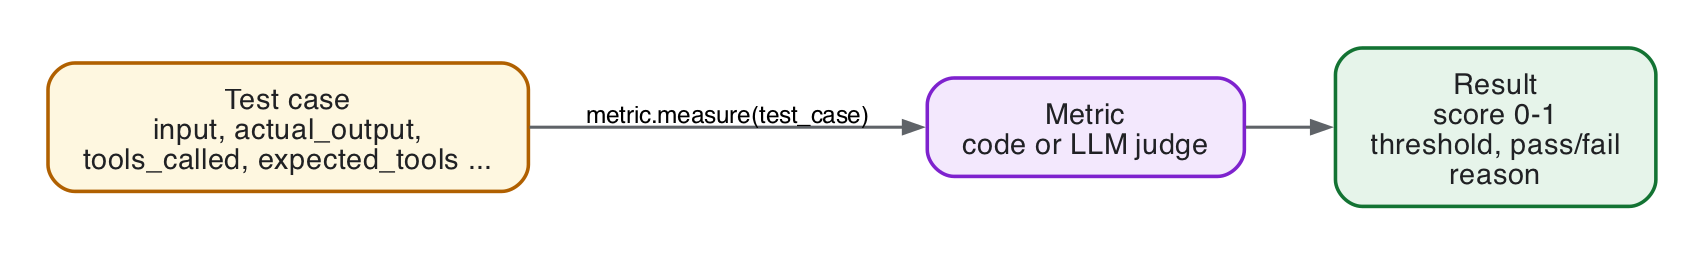

In this notebook we look at each piece: the test case format, how a metric scores, and what really happens inside an LLM judge.

## Setup

```bash
pip install -U deepeval
```

DeepEval uses OpenAI as its default judge, so it needs `OPENAI_API_KEY` in the `.env` file.

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv()                                     # reads OPENAI_API_KEY from .env
os.environ["DEEPEVAL_TELEMETRY_OPT_OUT"] = "YES"  # optional: turn off DeepEval usage stats

## Part 1: the test case format

A test case is **one run of the agent, written down**. It is an `LLMTestCase` with these fields:

| Field | What it holds | Who writes it | Which metrics use it |
|---|---|---|---|
| `input` | what the user asked | you (the test) | all |
| `actual_output` | what the agent answered | the agent | most |
| `expected_output` | a correct answer | you | correctness checks (G-Eval) |
| `tools_called` | the tools the agent called, in order | the agent | Tool Correctness, Argument Correctness, Tool Permission |
| `expected_tools` | the tools it should have called | you | Tool Correctness |

Each tool call is a `ToolCall`:

| Field | What it holds |
|---|---|
| `name` | the tool's name, for example `"search_flights"` |
| `input_parameters` | the arguments, for example `{"origin": "JFK", "destination": "LHR"}` |
| `output` | what the tool returned (optional) |

In [ ]:
from deepeval.test_case import LLMTestCase, ToolCall

test_case = LLMTestCase(
    input="Find me flights from New York to London.",
    actual_output="There are two flights: BA112 for $640 and VS4 for $520.",
    tools_called=[
        ToolCall(name="search_flights", input_parameters={"origin": "JFK", "destination": "LHR"}),
    ],
    expected_tools=[
        ToolCall(name="search_flights"),
    ],
)
test_case

## Part 2: what a metric gives back

Call `metric.measure(test_case)`. Then read four things:

| Attribute | Meaning |
|---|---|
| `metric.score` | a number from 0 to 1 |
| `metric.threshold` | the minimum score that counts as a pass (default 0.5) |
| `metric.success` | `True` if `score >= threshold` |
| `metric.reason` | why it got this score |

In [ ]:
from deepeval.metrics import ToolCorrectnessMetric

metric = ToolCorrectnessMetric(async_mode=False)  # async_mode=False: needed inside a notebook
metric.measure(test_case)

print("score:    ", metric.score)
print("threshold:", metric.threshold)
print("success:  ", metric.success)
print("reason:   ", metric.reason)

## Part 3: two kinds of metrics

Every metric is one of two kinds:

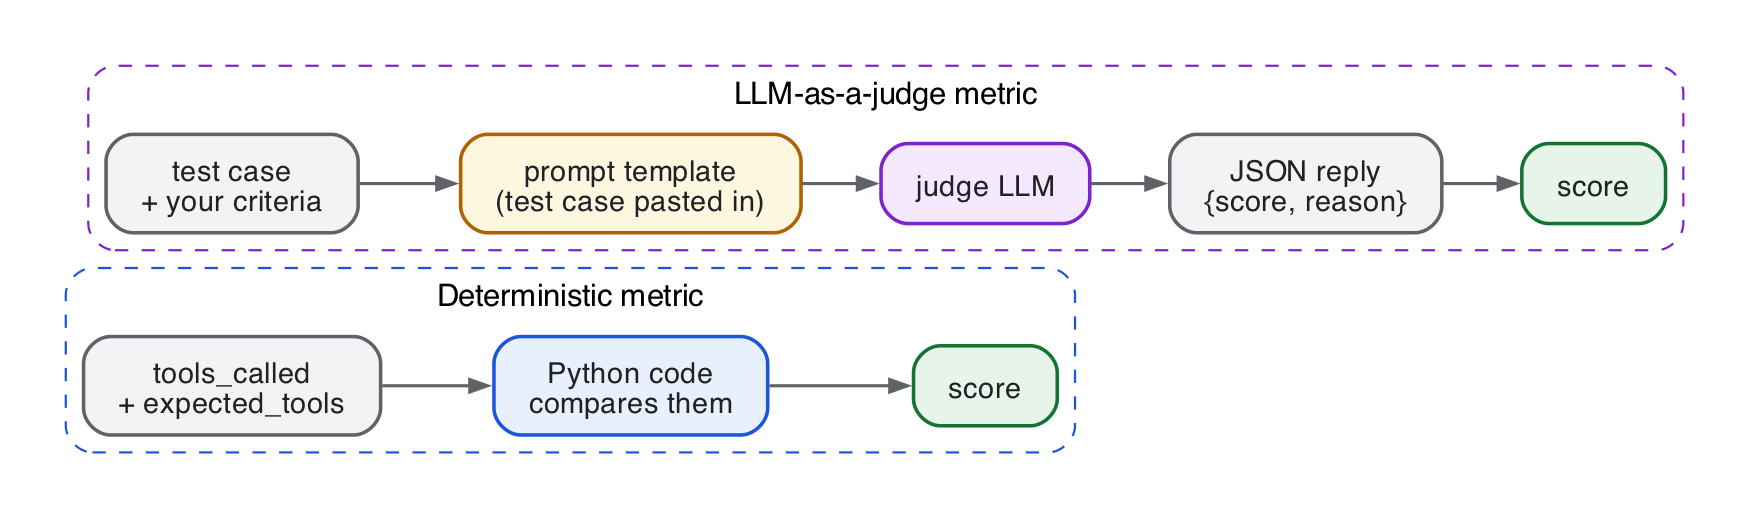

| | Deterministic | LLM-as-a-judge |
|---|---|---|
| How it scores | Python code compares fields | another LLM reads the test case and grades it |
| Needs | what you expected (for example `expected_tools`) | your criteria in plain English |
| Speed and cost | instant, free | a few seconds, costs tokens |
| Same result every time? | yes | almost, not 100% |
| Can judge meaning? | no | yes |

The agent metrics in DeepEval, by kind:

| Metric | Kind | Question it answers |
|---|---|---|
| `ToolCorrectnessMetric` | deterministic | were the expected tools called (and in the right order)? |
| `ToolPermissionMetric` | deterministic | did it only use allowed tools? |
| `AgentLoopDetectionMetric` | deterministic | did it repeat the same call again and again? |
| `ArgumentCorrectnessMetric` | LLM judge | were the tool arguments right for the request? |
| `TaskCompletionMetric` | LLM judge | was the task actually done? |
| `StepEfficiencyMetric` | LLM judge | were there unnecessary steps? |
| `PlanQualityMetric`, `PlanAdherenceMetric` | LLM judge | was the plan good, and was it followed? |
| `GEval` | LLM judge | **any rule you write in plain English** |

## Part 4: deterministic metrics, by example

A helper that runs one metric on one test case and prints the result:

In [ ]:
def check(test_case, metric):
    metric.async_mode = False  # run one step at a time: Jupyter already has its own async loop
    metric.measure(test_case)
    print("PASS" if metric.success else "FAIL", f"| score {metric.score:.2f}")
    print(metric.reason, "\n")

**Wrong tool.** The customer wanted flights, the agent read the baggage policy:

In [ ]:
wrong_tool = LLMTestCase(
    input="Find me flights from New York to London.",
    actual_output="You can bring one cabin bag of 8 kg.",
    tools_called=[ToolCall(name="get_baggage_policy")],
    expected_tools=[ToolCall(name="search_flights")],
)
check(wrong_tool, ToolCorrectnessMetric())

**Wrong order.** It booked before it searched. `should_consider_ordering=True` makes the order count, and `strict_mode=True` means all or nothing (score 1 or 0):

In [ ]:
wrong_order = LLMTestCase(
    input="Book the cheapest flight from New York to London for Priya Sharma.",
    actual_output="I booked VS4 for Priya Sharma.",
    tools_called=[ToolCall(name="book_flight"), ToolCall(name="search_flights")],
    expected_tools=[ToolCall(name="search_flights"), ToolCall(name="book_flight")],
)
check(wrong_order, ToolCorrectnessMetric(should_consider_ordering=True, strict_mode=True))

**Extra tools.** Careful: by default Tool Correctness only checks that the expected tools **were** called.
Calling **more** tools than expected still passes. `should_exact_match=True` requires exactly the expected list:

In [ ]:
extra_booking = LLMTestCase(
    input="Find me flights from New York to London.",
    actual_output="I found VS4 and booked it for you.",
    tools_called=[ToolCall(name="search_flights"), ToolCall(name="book_flight")],
    expected_tools=[ToolCall(name="search_flights")],
)
print("Default:")
check(extra_booking, ToolCorrectnessMetric())
print("Exact match:")
check(extra_booking, ToolCorrectnessMetric(should_exact_match=True))

**Forbidden tool.** The customer asked to change a seat, and the agent cancelled the booking:

In [ ]:
from deepeval.metrics import ToolPermissionMetric

forbidden_tool = LLMTestCase(
    input="Can I change my seat on booking BK-VS4?",
    actual_output="I have cancelled booking BK-VS4.",
    tools_called=[ToolCall(name="cancel_booking", input_parameters={"booking_id": "BK-VS4"})],
)
check(forbidden_tool, ToolPermissionMetric(allowed_tools=["search_flights", "book_flight", "get_baggage_policy"]))

### There is no magic: write your own

A deterministic metric is just a Python class with a `measure` method that sets `score`, `success` and `reason`.
Here is one that fails if the agent makes more than two tool calls:

In [ ]:
from deepeval.metrics import BaseMetric


class MaxToolCalls(BaseMetric):
    """Fails if the agent used more tool calls than allowed. Plain Python, no LLM."""

    def __init__(self, max_calls=2):
        self.max_calls = max_calls
        self.threshold = 1.0

    def measure(self, test_case, *args, **kwargs):
        number_of_calls = len(test_case.tools_called or [])
        self.score = 1.0 if number_of_calls <= self.max_calls else 0.0
        self.success = self.score >= self.threshold
        self.reason = f"The agent made {number_of_calls} tool calls (limit: {self.max_calls})."
        return self.score

    async def a_measure(self, test_case, *args, **kwargs):
        return self.measure(test_case)

    def is_successful(self):
        return self.success

    @property
    def __name__(self):
        return "Max tool calls"

In [ ]:
three_calls = LLMTestCase(
    input="Book the cheapest flight from New York to London for Priya Sharma.",
    actual_output="Booked VS4.",
    tools_called=[ToolCall(name="search_flights"), ToolCall(name="search_flights"), ToolCall(name="book_flight")],
)
check(three_calls, MaxToolCalls(max_calls=2))

## Part 5: LLM-as-a-judge, by example

Some things code cannot check. Here the agent called the right tool, but **swapped the cities**: it searched London to New York.

In [ ]:
swapped_cities = LLMTestCase(
    input="Find me flights from New York to London.",
    actual_output="There are three flights from London to New York.",
    tools_called=[ToolCall(name="search_flights", input_parameters={"origin": "LHR", "destination": "JFK"})],
    expected_tools=[ToolCall(name="search_flights")],
)
check(swapped_cities, ToolCorrectnessMetric())

Tool Correctness **passes**: it only compares tool names.
`ArgumentCorrectnessMetric` is an LLM judge: it reads the request and the arguments, and decides if they make sense.
(In a notebook we pass `async_mode=False`, because Jupyter already runs its own async loop.)

In [ ]:
from deepeval.metrics import ArgumentCorrectnessMetric

check(swapped_cities, ArgumentCorrectnessMetric(async_mode=False))

### What is really happening inside an LLM judge?

An LLM judge is **a prompt**. DeepEval has a prompt template for each metric, pastes your test case into it,
sends it to a model, and reads a JSON answer back.

To see it, we use a "spy" judge: the normal OpenAI judge, but it keeps a copy of every prompt and every reply.

In [ ]:
from deepeval.models import OpenAIModel


class SpyJudge(OpenAIModel):
    """The normal OpenAI judge, but it keeps a copy of every prompt it gets and every reply it gives."""

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conversation = []  # a list of (prompt, reply) pairs

    def generate(self, prompt, *args, **kwargs):
        reply = super().generate(prompt, *args, **kwargs)
        self.conversation.append((prompt, reply[0]))
        return reply

    def generate_raw_response(self, prompt, *args, **kwargs):  # G-Eval uses this one to get the score
        reply = super().generate_raw_response(prompt, *args, **kwargs)
        self.conversation.append((prompt, reply[0].choices[0].message.content))
        return reply


def show_conversation(judge):
    """Print every prompt DeepEval sent to the judge, and what the judge answered."""
    for number, (prompt, reply) in enumerate(judge.conversation, start=1):
        print(f"==================== PROMPT {number}: SENT TO THE JUDGE ====================")
        print(prompt)
        print(f"==================== REPLY {number}: FROM THE JUDGE ====================")
        print(reply, "\n")

Now the same Argument Correctness check, with the spy as the judge:

In [ ]:
judge = SpyJudge(model="gpt-4.1")
check(swapped_cities, ArgumentCorrectnessMetric(model=judge, async_mode=False))

The score came back. Now let's read the conversation DeepEval had with the judge:

In [ ]:
show_conversation(judge)

Read the prompts above. There were two calls:

1. **The verdict prompt**: "for each tool call, answer `yes` or `no`: do the arguments match the request?" with an example, then our test case pasted at the end.
   The judge replied `no`, because origin and destination are reversed.
2. **The reason prompt**: turns the verdicts into the one-sentence reason we see.

The score itself is computed with plain math: **correct tool calls ÷ all tool calls** = 0 ÷ 1 = 0.

### G-Eval: a judge for any rule you write

`GEval` lets you write your own criteria in plain English. Let's check a wrong answer about baggage:

In [ ]:
from deepeval.metrics import GEval
from deepeval.test_case import SingleTurnParams

wrong_baggage_answer = LLMTestCase(
    input="How many bags can I bring?",
    actual_output="You can bring as many bags as you like!",
    expected_output="One cabin bag of 8 kg is included. A checked bag of 23 kg costs $60 each way.",
)

correctness = GEval(
    name="Correctness",
    criteria="Is the actual output factually consistent with the expected output?",
    evaluation_params=[SingleTurnParams.INPUT, SingleTurnParams.ACTUAL_OUTPUT, SingleTurnParams.EXPECTED_OUTPUT],
    model=SpyJudge(model="gpt-4.1"),
    async_mode=False,
)
check(wrong_baggage_answer, correctness)

In [ ]:
show_conversation(correctness.model)

G-Eval made two calls:

1. **"Turn the criteria into evaluation steps."** From our one sentence, the judge wrote 3-4 concrete steps.
2. **"Follow these steps, score the test case from 0 to 10, and explain why."** Our `input`, `actual_output` and `expected_output` are pasted into the prompt.

DeepEval turns the 0-10 score into 0-1. That is the whole trick behind LLM-as-a-judge.

`evaluation_params` decides **which fields the judge can see**. Leave a field out, and the judge never sees it.

### Making a judge more reliable

| Tip | How |
|---|---|
| Same steps every run | write `evaluation_steps=[...]` yourself instead of `criteria` |
| Pass or fail, no middle | `strict_mode=True` |
| A stronger or cheaper judge | `model="gpt-4.1"` (the default in this DeepEval version is `gpt-5.4`) |
| Remember | a judge is an LLM too: read its reasons, it can be wrong |

## Summary

| You want to check | Use | Kind |
|---|---|---|
| Right tools, right order, nothing extra | `ToolCorrectnessMetric(should_exact_match=True)` | deterministic |
| Only allowed tools | `ToolPermissionMetric` | deterministic |
| No repeated calls | `AgentLoopDetectionMetric` | deterministic |
| Your own simple rule | a `BaseMetric` subclass | deterministic |
| Right arguments | `ArgumentCorrectnessMetric` | LLM judge |
| Right answer, or any rule in words | `GEval` | LLM judge |

**Next:** notebook 4, testing a real agent with many test cases.